# Binary Decision Tree Classifier



In [ ]:
from collections import Counter
from tqdm.notebook import tqdm

from copy import deepcopy

import numpy as np
np.random.seed(42)

from sklearn.model_selection import train_test_split
from sklearn.datasets import make_classification
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score

In [ ]:
X, y = make_classification(n_samples=1000, n_features = 10, n_informative=4, random_state=42)
x_train, x_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

# Intuition
- the idea is to maintain a list of indices corresponding to the training set samples as a property of the `DecisionTreeClassifier` class
  - lets call this `train_sample_indices`
- and the `DTNode` will rather contain the `start` and `end` values denoting the starting index of this index array.
  - say `curr_node.start = 2`, `curr_node.end = 5`, then the samples with indices = `dt.train_sample_indices[curr_node.start:curr_node.end+1]` correspond to the samples within this node `curr_node`.
- for each split, the subarray `x_train[dt.train_sample_indices[curr_node.start:curr_node.end+1]]` is the samples that have landed at this node.
  - for root node, `start = 0, end = n-1`, `n`: train set size
  - say `n = 10`, s.t. the split criterion led the samples with indices `[0, 1, 5, 8]` to go in the left node, and the remaining to the right node.
  - now, reshuffling of the `dt.train_sample_indices` would occur (remember `curr_node == root` here) s.t. all left-node indices are in the left and all right-node indices are in the right.
  - this would now change from the `dt.train_sample_indices` from `range(10)` to `[0,1,5,8,2,3,4,6,7,9]`
    - reshuffling changed the indices from `[0,1,2...9] --> [0,1,5,8,2,3,4,6,7,9]`
  - also,  `left_node.start = 0, left_node.end = 3, right_node.start = 4, right_node.end = 9`
  - these steps will now recursively occur, thus ensuring that the reshuffling will also occur at each node.

<font color="pink">`sklearn` alert!!</font>
- the reason you don't see this array in the `sklearn.DecisionTreeClassifier` (or regressor) class is because the actual tree was built by the **`C++` implementation**.
  - the python module of `sklearn` is just a wrapper on it.


# Implementation Summary
<font color="red">REMAINING!!</font>

In [ ]:
class DecisionTreeNode():
  def __init__(self, y, depth, indices_arr_start, indices_arr_end,
               feature = None, threshold = None):
    self.n_samples = len(y)
    self.depth = depth

    self.__indices_arr_start = indices_arr_start
    self.__indices_arr_end = indices_arr_end

    self.feature = feature
    self.threshold = threshold
    self.ig_max = None
    self.label_population = np.unique(y, return_counts=True)
    self.node_impurity = 1 - ((self.label_population[-1]/self.n_samples) ** 2).sum()
    self.prediction = self.label_population[0][np.argmax(self.label_population[1])]

    self.id = None

    self.left = None
    self.right = None

  def get_start_end_indices(self):
    return self.__indices_arr_start, self.__indices_arr_end

  def __str__(self):
    return f"<ID = {self.id}, " \
           f"n_s = {self.n_samples}, " \
           f"values = {self.label_population[-1]}, " \
           f"impu = {round(self.get_impurity(), 3)}, depth = {self.get_depth()}, "\
           f"feature = {self.feature}, threshold = {round(self.threshold, 3) if self.threshold else self.threshold}, "\
           f"ig = {round(self.ig_max, 4) if self.ig_max else self.ig_max}, "\
           f"s = {self.__indices_arr_start}, e = {self.__indices_arr_end}>"

  def get_impurity(self):
    return self.node_impurity

  def get_depth(self):
    return self.depth

In [ ]:
class MccpDecisionTree():
  """
  A class to store the MCCP-tree

  Attributes:
    left_children (np.ndarray): index of the left child
    right_children (np.ndarray): index of the right child
    feature (np.ndarray): index of the feature to be split on
    threshold (np.ndarray): threshold value to be used while splitting
    predictions (np.ndarray): predicted class as per i'th node
    node_impurities (np.ndarray): i'th node's impurity
  """
  def __init__(self,
               is_not_pruned,
               left_children, right_children,
               feature, threshold,
               predictions,
               original_dt_root,
               verbose = 0):
    self.is_not_pruned = is_not_pruned
    self.left_children = left_children
    self.right_children = right_children
    self.feature = feature
    self.threshold = threshold
    self.predictions = predictions
    self.root = original_dt_root

    self.node_impurities, self.node_num_samples = None, None
    self.subtree_size, self.subtree_impurity = None, None

    self.fetch_node_level_details(verbose)
    self.get_subtree_properties(verbose)

  def fetch_node_level_details(self, verbose = 0):
    # find the node-level impurities in an array representation
    # TODO: in the nodeless implementation, this should be done while
    # creating the main tree
    node_impurities = np.full(shape = (self.is_not_pruned.shape[0],), fill_value = np.inf)
    node_num_samples = np.zeros(shape = (self.is_not_pruned.shape[0],))
    bfs_arr = [self.root]
    while bfs_arr:
      curr_node = bfs_arr.pop()
      node_impurities[curr_node.id] = curr_node.get_impurity()
      node_num_samples[curr_node.id] = curr_node.n_samples
      if curr_node.left is not None:
        bfs_arr.append(curr_node.left)
      if curr_node.right is not None:
        bfs_arr.append(curr_node.right)

    self.node_impurities, self.node_num_samples = node_impurities, node_num_samples

  def get_subtree_properties(self, verbose = 0):
    # post-order traversal to know:
    #   1. subtree size
    #   2. subtree total impurity

    subtree_size = np.zeros(len(self.left_children), dtype=np.int64)
    subtree_impurity = np.zeros(len(self.left_children))

    # start post-order traversal from the root
    curr_node = 0

    # post-order traversal stack
    po_stack = [curr_node]

    # visited
    visited = np.full(shape = (len(self.left_children)), fill_value=False)

    while po_stack:
      # if verbose:
      #   print(po_stack, "\n", visited, "\n\n")
      if self.is_not_pruned[curr_node]:
        # curr_node shouldn't be pruned
        if not visited[curr_node]:
          visited[curr_node] = True

          if curr_node != self.left_children[curr_node]:
            #  if current node is a non-leaf node
            po_stack.append(self.right_children[curr_node])
            po_stack.append(self.left_children[curr_node])
            curr_node = self.left_children[curr_node]
          else:
            # current node is a leaf
            subtree_size[curr_node] = 1
            # if verbose:
            #   print(f"subtree_size[{curr_node}] = {subtree_size[curr_node]}")
            subtree_impurity[curr_node] = self.node_impurities[curr_node]
            if po_stack:
              if po_stack[-1] == curr_node:
                po_stack.pop(-1)
              if po_stack:
                # curr_node = po_stack[-1] if not visited[po_stack[-1]] else po_stack.pop(-1)
                curr_node = po_stack[-1]
              # if verbose:
              #   print(f"will now be dealing with node {curr_node}")
        else:
          # if verbose:
          #   print(f"curr_node = {curr_node}\n")
          if curr_node != self.left_children[curr_node]:
            # current node is a visited non-leaf node, hence its processing will
            # be remaining

            # subtree rooted at current node = 1 + left-subtree size + right-subtree size
            subtree_size[curr_node] = 1 + subtree_size[self.left_children[curr_node]] + subtree_size[self.right_children[curr_node]]
            # if verbose:
            #   print(f"subtree_size[{curr_node}] = 1 + "
            #         f"subtree_size[{self.left_children[curr_node]}] + "
            #         f"subtree_size[{self.right_children[curr_node]}]"
            #         f"= 1 + {subtree_size[self.left_children[curr_node]]} "
            #         f"+ {subtree_size[self.right_children[curr_node]]}")

            # consider the simplest non-leaf node: both children are leafs
            # subtree_impurity = (left_leaf_n_samples/curr_node_n_samples)*left_leaf_impurity + (right_leaf_n_samples/curr_node_n_samples)*right_leaf_impurity
            # ls_i, rs_i = left_leaf_impurity, right_leaf_impurity
            # ls_wgt, rs_wgt = left_leaf_n_samples, right_leaf_n_samples
            # ls_wi = left_leaf_impurity * left_leaf_n_samples
            # rs_wi = right_leaf_impurity * right_leaf_n_samples
            # subtree_impurity = (ls_wi + rs_wi)/curr_node_n_samples
            # note: this is the original subtree_impurity formula
            # and is recursively applicable on nodes having non-leaf children
            ls_impurity = subtree_impurity[self.left_children[curr_node]]
            ls_wgt = self.node_num_samples[self.left_children[curr_node]]
            ls_wgt_impurity = ls_impurity*ls_wgt

            rs_impurity = subtree_impurity[self.right_children[curr_node]]
            rs_wgt = self.node_num_samples[self.right_children[curr_node]]
            rs_wgt_impurity = rs_impurity*rs_wgt

            subtree_impurity[curr_node] = (ls_wgt_impurity + rs_wgt_impurity)/self.node_num_samples[curr_node]

          if po_stack:
              if po_stack[-1] == curr_node:
                po_stack.pop(-1)
              if po_stack:
                # curr_node = po_stack[-1] if not visited[po_stack[-1]] else po_stack.pop(-1)
                curr_node = po_stack[-1]
      else:
        # if current node is a pruned node, skip it
        # and pick the next node in the remaining stack
        if po_stack:
          curr_node = po_stack.pop(-1)

    self.subtree_size, self.subtree_impurity = subtree_size, subtree_impurity

  def vectorized_error(self, X, y, verbose = 0):
    # node_ids will store the ids of all leafs each sample
    # ultimately falls inside of, hence the shape = n_samples

    # initially, all samples lie in the root node
    node_ids = np.zeros(X.shape[0], dtype=np.int64)

    # loop to propagate all samples to their apt leafs
    while True:
      # grab the feature to be split at the current node of each sample
      feat = self.feature[node_ids]

      # grab the corresponding threshold to compare the feature value against
      thresh = self.threshold[node_ids]

      # if verbose != 0 and verbose != 1:
      #   print(f"Evaluating feature {feat} at threshold {thresh}")
      # if verbose:
      #   print(f"node_ids = {node_ids}\n")


      # check which sample should go in the left-child or the right-child
      # of the current node they currently reside in

      # True: take left-subtree, False: take right-subtree
      # special-case: if a sample is already at their apt leaf,
      # even then the mask == True
      feat_mask = X[np.arange(X.shape[0]), feat] <= thresh
      # this indexing ensures that for the i'th row being selected of X,
      # select the feat[i]'th column of X
      # hence, the output array `X[np.arange(X.shape[0]), feat]` is a 1d array,
      # with output[i] = X[i, feat[i]]
      # note that feat.shape = (X.shape[0],) as node_ids.shape = X.shape[0]
      new_node_ids = np.where(
          feat_mask,
          self.left_children[node_ids],
          self.right_children[node_ids]
      )

      # if verbose:
      #   print(f"new node ids = {new_node_ids}\n")

      if (new_node_ids == node_ids).all():
        # no change of current-node-ids for all samples, implying that all
        # samples have reached their appropriate leafs
        break

      # copy the new node-assignments per sample,
      # useful for the next iteration
      node_ids = new_node_ids.copy()
    if verbose:
      print(f"are all predicted node ids valid = {self.is_not_pruned[node_ids].all()}")
    # for all leaf nodes, return their corresponding prediction
    y_pred = self.predictions[node_ids]

    return 1 - accuracy_score(y, y_pred)

In [ ]:
class myDT():
  def __init__(self, max_depth, min_samples_split, min_samples_leaf, mccp = False):
    # DT hyperparameters - prepruning
    self.max_depth = max_depth
    self.min_samples_split = min_samples_split
    self.min_samples_leaf = min_samples_leaf
    self.indices_arr = None

    # DT hyperparameters - post pruning
    self.mccp = mccp
    self.mccp_tree = None

    # the actual tree
    # once the tree is created, this is the root node
    self.tree = None

    # DT important attributes for vectorized prediction
    # TODO: implement a nodeless DT using only the following as DT attributes
    self.left_children = None
    self.right_children = None
    self.num_node_samples = None
    self.node_predictions = None
    self.num_nodes = None
    self.feature = None
    self.threshold = None

  def create_node(self, y, depth, indices_arr_start, indices_arr_end,
               feature = None, threshold = None):
    return DecisionTreeNode(y, depth, indices_arr_start, indices_arr_end,
               feature = None, threshold = None)

  def fetch_children_given_feature(
      self,
      curr_node,
      X, y,
      feat_index, feat_thresh):

    curr_node.feature = feat_index
    curr_node.threshold = feat_thresh

    curr_node_start_idx, curr_node_end_idx = curr_node.get_start_end_indices()

    left_idx_mask = X[
        self.indices_arr[curr_node_start_idx:curr_node_end_idx+1],
        feat_index] < feat_thresh
    right_idx_mask = ~left_idx_mask

    left_indices = self.indices_arr[curr_node_start_idx:curr_node_end_idx+1][left_idx_mask]
    right_indices = self.indices_arr[curr_node_start_idx:curr_node_end_idx+1][right_idx_mask]

    # reshuffle
    self.indices_arr[curr_node_start_idx:curr_node_end_idx+1] = np.concatenate((
        left_indices,
        right_indices
    ))

    left_node = self.create_node(
        y = y[left_indices],
        depth = curr_node.get_depth()+1,
        indices_arr_start = curr_node_start_idx,
        indices_arr_end = curr_node_start_idx + left_indices.shape[0]-1
    )

    right_node = self.create_node(
        y = y[right_indices],
        depth = curr_node.get_depth()+1,
        indices_arr_start = curr_node_start_idx + left_indices.shape[0],
        indices_arr_end = curr_node_end_idx
    )

    return left_node, right_node

  def get_split_ig(self, curr_node, X, y, feat_index, mp_val):
    """
      Information gain
    """
    curr_node_start_idx, curr_node_end_idx = curr_node.get_start_end_indices()

    left_idx_mask = X[
        self.indices_arr[curr_node_start_idx:curr_node_end_idx+1],
        feat_index] < mp_val
    right_idx_mask = ~left_idx_mask

    left_indices = self.indices_arr[curr_node_start_idx:curr_node_end_idx+1][left_idx_mask]
    right_indices = self.indices_arr[curr_node_start_idx:curr_node_end_idx+1][right_idx_mask]

    left_n_samples, right_n_samples = left_indices.shape[0], right_indices.shape[0]

    # pre-pruning check
    if curr_node.n_samples < self.min_samples_split or \
      left_n_samples < self.min_samples_leaf or \
      right_n_samples < self.min_samples_leaf:
      return -1

    left_impurity = 1 - ((np.unique(y[left_indices], return_counts = True)[-1]/left_n_samples) ** 2).sum()
    right_impurity = 1 - ((np.unique(y[right_indices], return_counts = True)[-1]/right_n_samples) ** 2).sum()

    children_impurity = (left_n_samples/curr_node.n_samples)*left_impurity + (right_n_samples/curr_node.n_samples)*right_impurity
    return curr_node.get_impurity() - children_impurity


  def get_best_split_for_feat(self, curr_node, X, y, feat_index):
    curr_node_start_idx, curr_node_end_idx = curr_node.get_start_end_indices()
    feat_uniq_vals = np.unique(X[self.indices_arr[curr_node_start_idx:curr_node_end_idx+1], feat_index]).tolist()
    if len(feat_uniq_vals) > 1:
      child_node_depth = curr_node.get_depth()+1
      # will have at least 1 mid point
      midpoints = [round((feat_uniq_vals[i]+feat_uniq_vals[i+1])/2, 3)
                  for i in range(len(feat_uniq_vals)-1)]
      ig_max, best_thresh = -1, None
      for mp_val in midpoints:
        ig = self.get_split_ig(curr_node, X, y, feat_index, mp_val)
        if ig_max < ig:
          # print(f"\t{round(curr_node.get_impurity(), 3)}, {curr_node.label_population}"
          #       f" feature {feat_index},thresh = {mp_val} with left node "
          #       f" = {round(left_node.get_impurity(), 3)} ({left_node.label_population}),"
          #       f"right node  = {round(right_node.get_impurity(), 3)} ({right_node.label_population}).")
          ig_max = ig
          best_thresh = mp_val
      return feat_index, best_thresh, ig_max
    else:
      # no point in splitting using this feature,
      # all nodes already have the same feature value
      return None, None, -1


  def split_node(self, curr_node, X, y, verbose = 0):
    curr_max_split_gain = -1
    best_feat, best_feat_thresh = None, None
    if verbose >= 2:
      print(f"{' '*curr_node.get_depth()}Splitting node with samples = {curr_node.n_samples} and impurity = {curr_node.get_impurity()}")
    loop_obj = tqdm(range(X.shape[-1]), "Processing all features to find the best split at current node...") if verbose >= 2 else range(X.shape[-1])
    for feat_index in loop_obj:
      # iterate through each feature
      feat, thresh, split_gain = self.get_best_split_for_feat(
                                                              curr_node,
                                                              X,
                                                              y,
                                                              feat_index)
      if verbose >= 2:
        print(feat, thresh, split_gain)

      if split_gain > curr_max_split_gain:
        curr_max_split_gain = split_gain
        best_feat = feat
        best_feat_thresh = thresh

    if best_feat is not None and curr_max_split_gain > 0:
      # some split resulting in a positive information gain is found

      left_node, right_node = self.fetch_children_given_feature(curr_node,
                                                                X, y,
                                                    best_feat, best_feat_thresh)
      if verbose >= 2:
        print(f"Best feature is {best_feat} having threshold = {thresh}\n"
            f"with {left_node.n_samples} in left"
            f" and {right_node.n_samples} in right"
        )
      curr_node.ig_max = curr_max_split_gain
      return left_node, right_node
    return None, None

  def node_numbering(self, verbose=0):
    # pre-order traversal based numbering.
    # root, left, right

    # initialise the stack with root node
    pre_order_stack = [self.tree]

    # initialise the global index which'll be used to number all nodes
    global_idx = 0

    while pre_order_stack:
      # process the stack till it is empty

      # pop the top node
      top_node = pre_order_stack.pop(-1)

      # number this node
      top_node.id = global_idx
      global_idx += 1

      # push the right-node first as per pre-order traversal's
      # stack implementation (so that right node gets processed
      # after the left node has been processed)
      if top_node.right:
        pre_order_stack.append(top_node.right)

      # push the left-node after the right-node as per pre-order traversal's
      # stack implementation (so that left node gets processed
      # before the right node)
      if top_node.left:
        pre_order_stack.append(top_node.left)

    # store the total no. of nodes forming this decision tree
    # also useful while initialising the child-indices arrays
    self.num_nodes = global_idx

  def populate_post_numbering_attributes(self, verbose = 0):
    '''
      1. left and right children arrays
      2. node predictions
      3. feature and threshold arrays
    '''

    # initialize the left and right chilren attribute arrays
    # and the node_prediction attribute
    self.left_children = np.full((self.num_nodes,), -1)
    self.right_children = np.full((self.num_nodes,), -1)
    self.num_node_samples = np.full((self.num_nodes,), -1)
    self.node_predictions = np.full((self.num_nodes,), np.NAN)
    self.feature = np.full((self.num_nodes,), -1)
    self.threshold = np.full((self.num_nodes,), -1.0)

    # BFS-traversal of the tree
    bfs_arr = [self.tree]
    while bfs_arr:
      curr_node = bfs_arr.pop()

      self.num_node_samples[curr_node.id] = curr_node.n_samples
      self.node_predictions[curr_node.id] = curr_node.prediction

      # for each node, store its feature and threshold into the
      # tree-attribute arrays
      if curr_node.feature is not None:
        self.feature[curr_node.id] =  curr_node.feature
        self.threshold[curr_node.id] = curr_node.threshold

      if verbose >= 2:
        # print(f"Curr node: Id = {curr_node.id}, Feature = {curr_node.feature}, Threshold = {curr_node.threshold}")
        print(f"After processing ID = {curr_node.id},\n"
        f" Feature array = {self.feature}\n  Threshold array = {self.threshold}\n\n")

      # check for presence of left-child of current node
      if curr_node.left:
        self.left_children[curr_node.id] = curr_node.left.id
        bfs_arr.append(curr_node.left)
      else:
        # the node is its own left_child
        self.left_children[curr_node.id] = curr_node.id


      # check for presence of right-child of current node
      if curr_node.right:
        self.right_children[curr_node.id] = curr_node.right.id
        bfs_arr.append(curr_node.right)
      else:
        # the node is its own right_child
        self.right_children[curr_node.id] = curr_node.id

  def min_cost_complexity_pruning(self, x_val, y_val, verbose=0):
    """
      Steps:
      1. starting with the D.T. T_0, find effective alpha for each subtree
      2. prune the subtree with the lowest effective alpha to obtain T_1
      3. repeat steps 1-2 for T_1 to obtain T_2, and continue till
         T_m == single node
      4. choose the tree T_i with the least validation-set classification error

      Effective alpha: for a given subtree T rooted at node t,
        effective-alpha(t) = (R(t) - R(T))/(|T_t| - 1)
        - R(t): impurity at node t
        - R(T): impurity of T = sum of impurity of all leafs of T
        - |T_t| = node count of T including t
    """
    # pruning will be logical instead of physical,
    # similar to logical vs physical delete in D.E.

    node_id_list = np.arange(self.num_nodes)

    # in the original tree, no node is pruned
    is_not_pruned = np.full(shape = (self.num_nodes,), fill_value = True, dtype = bool)

    # create the MCCP tree representing the current tree
    curr_tree = MccpDecisionTree(
        is_not_pruned = is_not_pruned,
        left_children=self.left_children,
        right_children=self.right_children,
        feature=self.feature,
        threshold=self.threshold,
        predictions=self.node_predictions,
        original_dt_root = self.tree,
        verbose = verbose
    )

    # if verbose:
    #   print(f"\nnode_impurities for initial MCCP = {curr_tree.node_impurities}\n")
    #   print(f"subtree_sizes for initial MCCP = {curr_tree.subtree_size}\n")
    #   print(f"subtree_impurities for initial MCCP = {curr_tree.subtree_impurity}\n")

    temp_lc, temp_rc = self.left_children.copy(), self.right_children.copy()

    best_tree, min_val_err = curr_tree, None

    num_nodes = self.num_nodes
    n_iter = 10

    while n_iter and num_nodes != 1:
      # iterate through all non-pruned non-leaf nodes, evaluate alpha
      alpha_values = np.full(shape = (self.num_nodes,), fill_value = np.inf)
      for node_idx in np.arange(self.num_nodes):
        if curr_tree.is_not_pruned[node_idx] and \
          curr_tree.left_children[node_idx] != node_idx:
          alpha_values[node_idx] = (curr_tree.node_impurities[node_idx] - curr_tree.subtree_impurity[node_idx])/(curr_tree.subtree_size[node_idx] - 1)

      # prune the subtree having the least complex root(node with the least alpha)
      prune_root = np.argmin(alpha_values)
      if verbose:
        print(f"\nalphas = {alpha_values}\n\n")
        print(f"\nSubtree rooted at node {prune_root} having alpha = {alpha_values[prune_root]} pruned when num_nodes = {num_nodes}")

      pruning_bfs_queue = [prune_root]
      while pruning_bfs_queue:
        cn = pruning_bfs_queue.pop()
        if is_not_pruned[cn]:
          if cn != prune_root:
            # don't prune the root of the subtree to prune
            is_not_pruned[cn] = False
          if temp_lc[cn] != cn:
            # non-leaf node being pruned
            pruning_bfs_queue.append(temp_lc[cn])
            pruning_bfs_queue.append(temp_rc[cn])

      # the node that's pruned will become its own child (i.e. becomes a leaf)
      temp_lc = np.where(is_not_pruned, temp_lc, node_id_list)
      temp_rc = np.where(is_not_pruned, temp_rc, node_id_list)
      temp_lc[prune_root] = prune_root
      temp_rc[prune_root] = prune_root

      # create the pruned tree required for the next iteration
      pruned_tree = MccpDecisionTree(
        is_not_pruned = is_not_pruned,
        left_children=temp_lc,
        right_children=temp_rc,
        feature=self.feature,
        threshold=self.threshold,
        predictions=self.node_predictions,
        original_dt_root = self.tree,
        verbose = verbose
      )
      pruned_tree_cv_score = pruned_tree.vectorized_error(x_val, y_val,
                                                          verbose = verbose)

      if verbose:
        print(f"after pruning node {prune_root} for MCCP tree with num_nodes = {num_nodes}"
              f"\npruned_tree_cv_score = {pruned_tree_cv_score}\n"
              f"\n is_not_pruned = {is_not_pruned}\n"
              f"\n lc = {temp_lc} \n"
              f"\n rc = {temp_rc} \n\n")


      if min_val_err is None or min_val_err > pruned_tree_cv_score:
        # found a better tree than the current best tree
        min_val_err = pruned_tree_cv_score
        best_tree = pruned_tree

      curr_tree = deepcopy(pruned_tree)
      num_nodes = np.count_nonzero(curr_tree.is_not_pruned)
      n_iter -= 1

    if verbose:
      print(f"Best MCCP pruned tree had a validation error of {round(min_val_err, 4)}")

    return best_tree

  def fit(self, X, y, verbose=0):

    x_train, y_train = X.copy(), y.copy()
    x_val, y_val = None, None

    if self.mccp:
      x_train, x_val, y_train, y_val = train_test_split(
          X,
          y,
          test_size = 0.15,
          random_state=42
      )
      if verbose:
        print(f"split training into {x_train.shape[0]} training and {x_val.shape[0]} validation samples.")

    self.indices_arr = np.arange(x_train.shape[0])

    # create the root of the DT
    root = self.create_node(y_train, depth=0, indices_arr_start = 0, indices_arr_end = self.indices_arr.max())

    # initialise the queue used to iteratively build the tree
    tree_q = [root]
    while tree_q:
      curr_node = tree_q.pop(0)
      if verbose >= 2:
        print(f"{' '*curr_node.get_depth()}Node found at depth = {curr_node.get_depth()} with samples = {curr_node.n_samples}")
      if curr_node.depth < self.max_depth and \
         curr_node.n_samples >= self.min_samples_split :
        # can continue building this subtree
        left_child, right_child = self.split_node(curr_node, x_train, y_train, verbose=verbose)
        if left_child is not None and right_child is not None and \
            left_child.n_samples >= self.min_samples_leaf and \
            right_child.n_samples >= self.min_samples_leaf:
          # valid split
          curr_node.left = left_child
          curr_node.right = right_child
          tree_q.append(left_child)
          tree_q.append(right_child)

    self.tree = root

    # number the nodes
    self.node_numbering()

    # find out the indices of the left and right child for each node,
    # , populate node predictions and populate the feature + threshold arrays
    self.populate_post_numbering_attributes(verbose = verbose)

    if self.mccp:
      # perform effective-alpha based minimum cost complexity pruning
      # this is a post-pruning method
      self.mccp_tree = self.min_cost_complexity_pruning(x_val, y_val, verbose = verbose)

  def predict(self, X):
    # sequential traversal
    # TODO: Vectorized traversal

    y_pred = []
    for i in tqdm(range(X.shape[0]), "Sequential prediction"):
      bfs = [self.tree]
      while bfs:
        curr_node = bfs.pop(0)
        if curr_node.feature is not None:
          # non-leaf node
          if X[i, curr_node.feature] < curr_node.threshold:
            # left-subtree traversal
            bfs.append(curr_node.left)
          else:
            # right-subtree traversal
            bfs.append(curr_node.right)
        else:
          # leaf node
          y_pred.append(curr_node.prediction)
          break
    if len(y_pred) != X.shape[0]:
      raise Exception("#predictions != #samples")
    return y_pred

  def vectorized_predict(self, X, verbose = 0):
    # node_ids will store the ids of all leafs each sample
    # ultimately falls inside of, hence the shape = n_samples

    # initially, all samples lie in the root node
    node_ids = np.zeros(X.shape[0], dtype=np.int64)

    # print(node_ids.dtype, node_ids)

    # loop to propagate all samples to their apt leafs
    while True:
      # grab the feature to be split at the current node of each sample
      feat = self.feature[node_ids]

      # grab the corresponding threshold to compare the feature value against
      thresh = self.threshold[node_ids]

      if verbose != 0 and verbose != 1:
        print(f"Evaluating feature {feat} at threshold {thresh}")
      if verbose:
        print(f"node_ids = {node_ids}\n")


      # check which sample should go in the left-child or the right-child
      # of the current node they currently reside in

      # True: take left-subtree, False: take right-subtree
      # special-case: if a sample is already at their apt leaf,
      # even then the mask == True
      feat_mask = X[np.arange(X.shape[0]), feat] <= thresh
      # this indexing ensures that for the i'th row being selected of X,
      # select the feat[i]'th column of X
      # hence, the output array `X[np.arange(X.shape[0]), feat]` is a 1d array,
      # with output[i] = X[i, feat[i]]
      # note that feat.shape = (X.shape[0],) as node_ids.shape = X.shape[0]
      if verbose:
        print(f"\nfeat_mask shape = {feat_mask.shape}, feat_mask = {feat_mask}\n")
      if feat_mask.ndim == 2:
        feat_mask = feat_mask.all(axis=1)
      new_node_ids = np.where(
          feat_mask,
          self.left_children[node_ids],
          self.right_children[node_ids]
      )

      if verbose:
        print(f"new node ids = {new_node_ids}\n")

      if (new_node_ids == node_ids).all():
        # no change of current-node-ids for all samples, implying that all
        # samples have reached their appropriate leafs
        break

      # copy the new node-assignments per sample,
      # useful for the next iteration
      node_ids = new_node_ids.copy()

    # for all leaf nodes, return their corresponding prediction
    return self.node_predictions[node_ids]

  def print_tree(self):
    # pre-order traversal: root.val then left.val then right.val
    pre_order_stack = [self.tree]
    while pre_order_stack:
      top_node = pre_order_stack.pop(-1)
      print(f"{'  '*top_node.get_depth()}{top_node}")
      if top_node.right is not None:
        pre_order_stack.append(top_node.right)
      if top_node.left is not None:
        pre_order_stack.append(top_node.left)

In [ ]:
my_dtc = myDT(max_depth = 4, min_samples_split = 20, min_samples_leaf = 10)
my_dtc.fit(x_train, y_train, verbose=0)

In [ ]:
# @title
my_dtc.print_tree()

<ID = 0, n_s = 800, values = [399 401], impu = 0.5, depth = 0, feature = 4, threshold = 0.287, ig = 0.1099, s = 0, e = 799>
  <ID = 1, n_s = 596, values = [379 217], impu = 0.463, depth = 1, feature = 2, threshold = 2.595, ig = 0.0574, s = 0, e = 595>
    <ID = 2, n_s = 464, values = [337 127], impu = 0.398, depth = 2, feature = 2, threshold = -1.457, ig = 0.0781, s = 0, e = 463>
      <ID = 3, n_s = 32, values = [32], impu = 0.0, depth = 3, feature = None, threshold = None, ig = None, s = 0, e = 31>
      <ID = 4, n_s = 432, values = [337  95], impu = 0.343, depth = 3, feature = 4, threshold = -0.919, ig = 0.0317, s = 32, e = 463>
        <ID = 5, n_s = 191, values = [176  15], impu = 0.145, depth = 4, feature = None, threshold = None, ig = None, s = 32, e = 222>
        <ID = 6, n_s = 241, values = [161  80], impu = 0.444, depth = 4, feature = None, threshold = None, ig = None, s = 223, e = 463>
    <ID = 7, n_s = 132, values = [42 90], impu = 0.434, depth = 2, feature = 6, threshold

In [ ]:
# @title
y_pred_mydtc = my_dtc.predict(x_test)
print(accuracy_score(y_test, y_pred_mydtc))

Sequential prediction:   0%|          | 0/200 [00:00<?, ?it/s]

0.83


In [ ]:
vectorized_y_pred_mydtc = my_dtc.vectorized_predict(x_test, verbose = 0).astype(np.int64)
print(accuracy_score(y_test, vectorized_y_pred_mydtc))

0.83


In [ ]:
my_dtc_ccp = myDT(max_depth = 4, min_samples_split = 20, min_samples_leaf = 10, mccp = True)
my_dtc_ccp.fit(x_train, y_train, verbose=1)

split training into 680 training and 120 validation samples.

alphas = [0.01435916 0.01585319 0.02352927        inf 0.01394197        inf
        inf 0.04490102 0.00348772        inf        inf 0.03132102
        inf        inf 0.02202639 0.01000394        inf 0.00052057
        inf        inf        inf]



Subtree rooted at node 17 having alpha = 0.0005205659578683616 pruned when num_nodes = 21
are all predicted node ids valid = True
after pruning node 17 for MCCP tree with num_nodes = 21
pruned_tree_cv_score = 0.14166666666666672

 is_not_pruned = [ True  True  True  True  True  True  True  True  True  True  True  True
  True  True  True  True  True  True False False  True]

 lc = [ 1  2  3  3  5  5  6  8  9  9 10 12 12 13 15 16 16 17 18 19 20] 

 rc = [14  7  4  3  6  5  6 11 10  9 10 13 12 13 20 17 16 17 18 19 20] 



alphas = [0.01594135 0.01585319 0.02352927        inf 0.01394197        inf
        inf 0.04490102 0.00348772        inf        inf 0.03132102
        inf        inf

In [ ]:
my_dtc_ccp.mccp_tree.is_not_pruned

array([ True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True])

In [ ]:
my_dtc_ccp.mccp_tree.subtree_size, my_dtc_ccp.mccp_tree.left_children, my_dtc_ccp.mccp_tree.right_children

(array([21, 13,  5,  1,  3,  1,  1,  7,  3,  1,  1,  3,  1,  1,  7,  5,  1,
         3,  1,  1,  1]),
 array([ 1,  2,  3,  3,  5,  5,  6,  8,  9,  9, 10, 12, 12, 13, 15, 16, 16,
        18, 18, 19, 20]),
 array([14,  7,  4,  3,  6,  5,  6, 11, 10,  9, 10, 13, 12, 13, 20, 17, 16,
        19, 18, 19, 20]))

In [ ]:
my_dtc.feature, my_dtc.threshold

(array([ 4,  2,  2, -1,  4, -1, -1,  6,  6, -1, -1,  0, -1, -1,  9,  0, -1,
         2, -1, -1, -1]),
 array([ 0.287,  2.595, -1.457, -1.   , -0.919, -1.   , -1.   ,  0.079,
        -0.142, -1.   , -1.   , -0.417, -1.   , -1.   ,  1.548, -1.95 ,
        -1.   ,  0.687, -1.   , -1.   , -1.   ]))

In [ ]:
my_dtc_ccp.feature, my_dtc_ccp.threshold

(array([ 4,  2,  2, -1,  4, -1, -1,  6,  9, -1, -1,  6, -1, -1,  9,  0, -1,
         4, -1, -1, -1]),
 array([ 0.287,  2.595, -1.457, -1.   , -0.919, -1.   , -1.   , -0.142,
         0.961, -1.   , -1.   ,  0.153, -1.   , -1.   ,  1.548, -1.828,
        -1.   ,  0.378, -1.   , -1.   , -1.   ]),
 True)

In [ ]:
my_dtc_ccp.mccp_tree

In [ ]:
y_pred_mydtc_ccp_original_tree = my_dtc_ccp.predict(x_test)
print(accuracy_score(y_test, y_pred_mydtc_ccp_original_tree))


Sequential prediction:   0%|          | 0/200 [00:00<?, ?it/s]

AttributeError: 'NoneType' object has no attribute 'feature'

In [ ]:
sklearn_dtc = DecisionTreeClassifier(max_depth = 4, min_samples_split = 20, min_samples_leaf = 10)
sklearn_dtc.fit(x_train, y_train)
print(accuracy_score(y_test, sklearn_dtc.predict(x_test)))
1

0.83


1

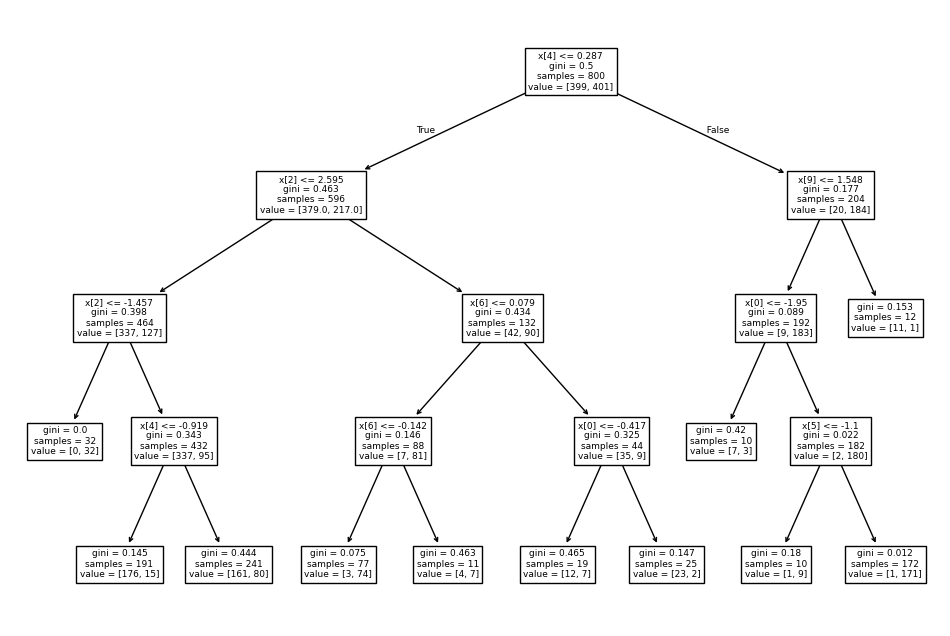

In [ ]:
import matplotlib.pyplot as plt

fig = plt.figure(figsize=(12, 8))
plot_tree(sklearn_dtc)
plt.show()

# Deriving associated time complexities

## Tree building
- $O(log(N).p.N.\mu_{max})$
  - $p : \textrm{ no. of features } $
  - $\mu_{max}: \textrm{cardinality of the feature with the highest cardinality, i.e. most no. of unique values } $
  - $N: \textrm{ no. of training samples} $
- $p$ term: since the algorithm iterates through all features
- $\mu_{max}$ term: since for each feature, the algorithm takes all possible **unique** values($\mu_p$), sorts them ($\mu_p.log(\mu_p)$), finds midpoints and then sequentially tests each midpoint ($\mu_p - 1$) to determine the best split threshold
  - the feature with the highest cardinality will take the most time
- $Nlog(N)$
  - at each depth, all nodes when combined will have an array size of $N$
  - at each depth, for each node at this depth, the algorithm will traverse all the samples at that node to:
    1. determine the unique values for that feature
    2. to identify which values are smaller and which are larger than the selected midpoint, being as a threshold.
  - across all nodes at this depth, this amounts to $N$ values iterated, hence at a depth $d$, for a given feature, the time is $O(N)$
  - $log(N)$, because there are these many depth values (height of the full binary tree), and at each depth a total of $O(N)$ values will be iterated.
- the actual time complexity is $O(log(N).(p.(\mu_{p}.N + \mu_{p}.log(\mu_{p}))))$, but:
  - upper bound of $\mu_p$, i.e. $\mu_{max}$ is $N$, hence the $\mu_p.N$ term dominates over $\mu_{p}.log(\mu_{p})$
- Explanation-1: height of tree = $O(log(N))$
  - worst case scenario: each training sample is a leaf node (lands up in a unique leaf node)
  - no. of leafs = N
  - for a tree with $N$ leaves, no. of remaining nodes of the tree (full-binary) = $N-1$
  - total no. of nodes = $2N-1 = O(N)$
  - for a full binary tree with $O(N)$ nodes, height = $log(N)$ \
  $$
  \textrm{no. of nodes at depth } d = 2^d \\
  \textrm{at final leaf level, i.e. } d = D,  2^D = N \Rightarrow D = Log(N)
  $$
-

## Prediction